# Array interference suppression
Complex $n=16,k=3$ interference-only training, independent held-out evaluation, and proper complex Gaussian noise. The orthonormal interference modes start from three ULA steering vectors; known diagonal phase motion accounts for half the physical motion. Desired orientation, training count, drift, unequal powers, correlation, and desired-signal contamination are varied separately.

The mean and modal decisions use exactly the same Bingham parameter and noise values. The EW PCA mode is identical to the Bingham mode; this is a control, not an omitted performance gain. Loaded covariance and Bingham forgetting are selected using three candidates each on separate seeded validation streams. Oracle covariance is an evaluation reference. See `benchmarks/case1/README.md` for references and omissions.

Four worker processes run independent trajectories with checksum-verified resumable checkpoints. Eight trajectories per scenario provide a reproducible pilot with explicit uncertainty intervals. Increase repeats and chain budgets before using lower-tail or coverage results as precise empirical claims. Sampling diagnostics are part of the result; a capped failed diagnostic is retained and reported.

In [1]:
from pathlib import Path
import sys, os, json
ROOT=Path.cwd() if (Path.cwd()/'lib').exists() else Path.cwd().parent
sys.path.insert(0,str(ROOT))
from lib.validation import require_gate
print('Theory gate:',require_gate(ROOT)['status'])
from lib.plotting import plt,save
from lib.reporting import run_or_load,coverage_table,error_curve
import numpy as np
import pandas as pd
from IPython.display import display
OUT=ROOT/'results'
# Set refresh=True to resimulate; cached tables are verified against source/config hashes.
config=dict(repeats=8,T=72,draws=6000,burnin=2500,max_draws=24000,max_burnin=8000)

result=run_or_load(ROOT,'case1',dict(seed=1729,workers=4,checkpoint_dir='results/checkpoints/array',**config))
m=result['metrics'];r=result['regions'];display(result['config'])

Theory gate: passed


case1: loading verified simulation tables


{'seed': 1729,
 'repeats': 8,
 'T': 72,
 'draws': 6000,
 'burnin': 2500,
 'n': 16,
 'k': 3,
 's': 0.3,
 'tau2': 2.0,
 'checkpoints': [12, 36, 72],
 'max_draws': 24000,
 'max_burnin': 8000,
 'coverage_distribution': 'Repeated independent observations of deterministic moving subspace paths',
 'known_motion_fraction': 0.5,
 'validation_candidates': 3,
 'evaluation_snapshots': 256,
 'nominal_mass': 0.95,
 'coverage_guaranteed': False,
 'workers': 4,
 'checkpoint_dir': 'results/checkpoints/array'}

## Matched decisions and drift
Held-out power and population SINR use unit desired-signal power. Error bars show one standard error across independent trajectories. Posterior-mean benefits need not hold for every realized true covariance.

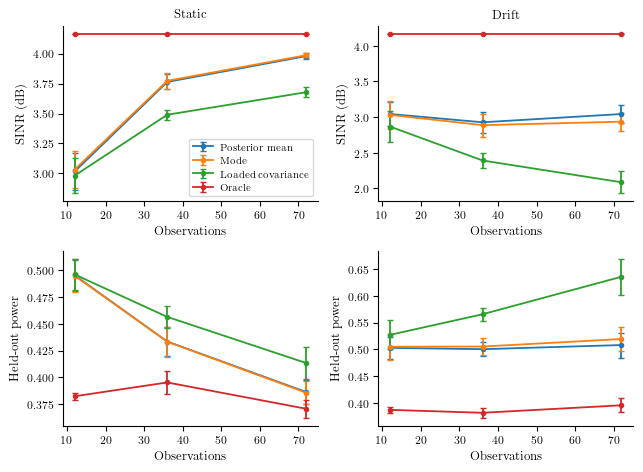

Largest Bingham/EW modal distance: 9.8843121241194e-08


In [2]:
fig,axs=plt.subplots(2,2,figsize=(6.5,4.8))
for col,scenario in enumerate(['Static','Drift']):
    subset=m[m.scenario==scenario]
    error_curve(axs[0,col],subset,'sinr_db',['Posterior mean','Mode','Loaded covariance','Oracle'])
    error_curve(axs[1,col],subset,'heldout_power',['Posterior mean','Mode','Loaded covariance','Oracle'])
    axs[0,col].set_title(scenario);axs[0,col].set_ylabel('SINR (dB)');axs[1,col].set_ylabel('Held-out power')
axs[0,0].legend();fig.tight_layout();save(fig,OUT/'array_tracking');plt.show()
print('Largest Bingham/EW modal distance:',m.ew_modal_distance.max())
assert m.ew_modal_distance.max()<1e-6


## Orientation and mismatch
The tenth-percentile SINR is computed across trajectories at the terminal time, not across correlated training snapshots. The same-rank isotropic model deliberately remains unchanged under mismatch. The numerical tables preserve unfavorable results.

mean_sinr  tail_sinr     power  \
scenario              method                                              
Contamination         Loaded covariance   2.565477   1.935527  0.559805   
                      Mode               -0.249560  -0.958980  1.073948   
                      Oracle              4.164234   4.164234  0.383333   
                      Posterior mean      0.139116  -0.501009  0.978047   
Correlation           Loaded covariance   3.729606   3.554252  0.423886   
                      Mode                3.934223   3.795346  0.404263   
                      Oracle              4.244581   4.244581  0.376307   
                      Posterior mean      3.969231   3.859923  0.400997   
Drift                 Loaded covariance   2.085715   1.450859  0.621328   
                      Mode                2.934908   2.529718  0.510312   
                      Oracle              4.164234   4.164234  0.383333   
                      Posterior mean      3.041821   2.693671  0.497758   
Far from interference Loaded covariance   4.584526   4.536064  0.347993   
                      Mode                4.383069   4.198550  0.364762   
                      Oracle              5.035736   5.035736  0.313636   
                      Posterior mean      4.405458   4.228923  0.362852   
Near interference     Loaded covariance  -1.922782  -2.198925  1.559614   
                      Mode               -1.506053  -1.785569  1.416415   
                      Oracle             -0.606978  -0.606978  1.150000   
                      Posterior mean     -1.498466  -1.765622  1.413780   
Static                Loaded covariance   3.677574   3.558289  0.428921   
                      Mode                3.986556   3.923341  0.399377   
                      Oracle              4.164234   4.164234  0.383333   
                      Posterior mean      3.979134   3.915922  0.400062   
Unequal powers        Loaded covariance   3.749275   3.453515  0.422485   
                      Mode                3.512256   3.278087  0.445947   
                      Oracle              4.490925   4.490925  0.355556   
                      Posterior mean      3.580279   3.343451  0.439000   

                                          heldout  
scenario              method                       
Contamination         Loaded covariance  0.539402  
                      Mode               1.031862  
                      Oracle             0.375602  
                      Posterior mean     0.940677  
Correlation           Loaded covariance  0.415297  
                      Mode               0.395323  
                      Oracle             0.372846  
                      Posterior mean     0.391832  
Drift                 Loaded covariance  0.635392  
                      Mode               0.519162  
                      Oracle             0.395556  
                      Posterior mean     0.508002  
Far from interference Loaded covariance  0.337416  
                      Mode               0.350167  
                      Oracle             0.301527  
                      Posterior mean     0.348440  
Near interference     Loaded covariance  1.537818  
                      Mode               1.410237  
                      Oracle             1.150792  
                      Posterior mean     1.404149  
Static                Loaded covariance  0.413425  
                      Mode               0.385801  
                      Oracle             0.370854  
                      Posterior mean     0.386446  
Unequal powers        Loaded covariance  0.430374  
                      Mode               0.454681  
                      Oracle             0.365605  
                      Posterior mean     0.447675

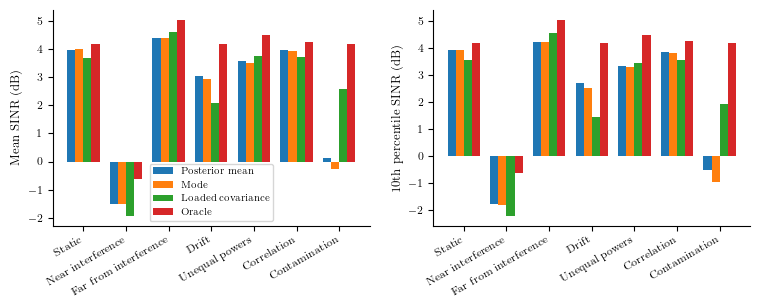

In [3]:
final=m[m.t==config['T']]
summary=final.groupby(['scenario','method']).agg(mean_sinr=('sinr_db','mean'),tail_sinr=('sinr_db',lambda x:x.quantile(.1)),power=('output_power','mean'),heldout=('heldout_power','mean'))
display(summary)
scenarios=list(final.scenario.unique());methods=['Posterior mean','Mode','Loaded covariance','Oracle']
fig,axs=plt.subplots(1,2,figsize=(9,2.8));x=np.arange(len(scenarios));width=.19
for j,method in enumerate(methods):
    g=summary.xs(method,level='method').reindex(scenarios)
    axs[0].bar(x+(j-1.5)*width,g.mean_sinr,width,label=method)
    axs[1].bar(x+(j-1.5)*width,g.tail_sinr,width,label=method)
for ax in axs:ax.set_xticks(x,scenarios,rotation=30,ha='right')
axs[0].set_ylabel('Mean SINR (dB)');axs[1].set_ylabel('10th percentile SINR (dB)');axs[0].legend()
save(fig,OUT/'array_mismatch');plt.show()


## Credible regions and leakage
Coverage is measured under repeated observations of deterministic paths with the stated forgetting rule. It is not guaranteed at 95%. Wilson intervals reflect only the finite trajectory count; sampler threshold errors are reported separately. Both regions use posterior mass 0.95. The HPD region can be wider in one task direction and narrower in another.

The optimization gap certifies Eq. (33) at the estimated region threshold, not the threshold itself. Sampling checks do not certify credible-tail accuracy. Failed diagnostics remain in the tables and are counted below.

,scenario,region,coverage,low,high,n
0,Contamination,Ball,0.00,0.000000,0.324416,8
1,Contamination,HPD,0.00,0.000000,0.324416,8
2,Correlation,Ball,1.00,0.675584,1.000000,8
3,Correlation,HPD,0.75,0.409270,0.928522,8
4,Drift,Ball,0.75,0.409270,0.928522,8
5,Drift,HPD,0.75,0.409270,0.928522,8
6,Far from interference,Ball,0.00,0.000000,0.324416,8
7,Far from interference,HPD,0.00,0.000000,0.324416,8
8,Near interference,Ball,0.75,0.409270,0.928522,8
9,Near interference,HPD,0.75,0.409270,0.928522,8


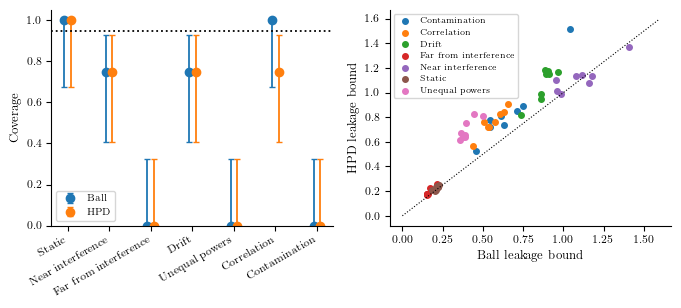

Largest optimization gap: 1.003824467549208e-06


In [4]:
posterior=final[final.method=='Posterior mean']
coverage=coverage_table(posterior);display(coverage)
fig,axs=plt.subplots(1,2,figsize=(8,2.8))
for region,offset in [('Ball',-.08),('HPD',.08)]:
    g=coverage[coverage.region==region].set_index('scenario').reindex(scenarios)
    axs[0].errorbar(np.arange(len(g))+offset,g.coverage,yerr=np.maximum(0,[g.coverage-g.low,g.high-g.coverage]),fmt='o',capsize=2,label=region)
axs[0].axhline(.95,color='k',ls=':');axs[0].set_xticks(x,scenarios,rotation=30,ha='right');axs[0].set_ylim(0,1.05);axs[0].set_ylabel('Coverage');axs[0].legend()
paired=r[r.t==config['T']].pivot(index=['scenario','repeat'],columns='region',values='upper')
for scenario,g in paired.groupby(level='scenario'):axs[1].scatter(g.Ball,g.HPD,s=16,label=scenario)
lim=max(paired.max())*1.05;axs[1].plot([0,lim],[0,lim],'k:',lw=.8);axs[1].set_xlabel('Ball leakage bound');axs[1].set_ylabel('HPD leakage bound');axs[1].legend(fontsize=6,loc='upper left')
save(fig,OUT/'array_regions');plt.show()
print('Largest optimization gap:',r.optimization_gap.max())
assert r.feasible.all() and r.optimization_gap.max()<1e-5


## Numerical accuracy and cost
Modal updates, posterior moments, and regional optimization are timed separately. `decision_seconds` includes cumulative modal updates and cumulative moment evaluations for the posterior-mean decision. The loaded covariance reference includes its own updates. Oracle timings include only the decision solve. Predictive covariance, fitted scalar noise, and modal basis are shared in the mean/modal comparison.

,pass_fraction,minimum_ess,largest_rhat,largest_mcse,mean_moment_seconds
scenario,,,,,
Contamination,1.0,53.032047,1.056671,0.008360,12.445274
Correlation,0.708333,32.611747,1.081174,0.013696,19.371481
Drift,1.0,50.527881,1.055699,0.012021,12.881854
Far from interference,0.958333,42.317950,1.070346,0.009595,12.384455
Near interference,1.0,51.704349,1.059905,0.011592,17.089297
Static,0.958333,43.520185,1.083540,0.010378,13.669807
Unequal powers,0.458333,14.039767,1.077311,0.012704,20.973104


,decision_seconds,update_seconds
method,,
Loaded covariance,0.011961,0.011764
Mode,0.024717,0.024515
Oracle,0.000140,0.000000
Posterior mean,46.659964,0.024515


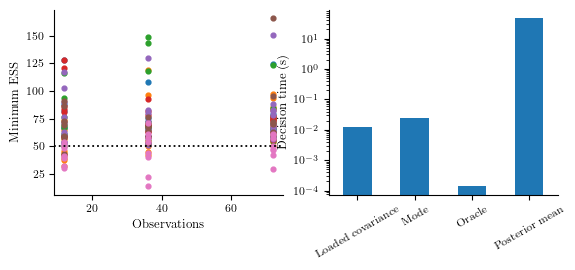

Failed sampling diagnostics: 22 of 168


,method,beta,loading,validation_loss,scenario
0,Bingham,0.94,NaN,0.423713,Static
1,Bingham,0.98,NaN,0.406571,Static
2,Bingham,1.00,NaN,0.402996,Static
3,Loaded covariance,0.94,0.05,0.562589,Static
4,Loaded covariance,0.98,0.20,0.448108,Static
5,Loaded covariance,1.00,0.80,0.416997,Static
6,Bingham,0.94,NaN,1.564825,Near interference
7,Bingham,0.98,NaN,1.527023,Near interference
8,Bingham,1.00,NaN,1.542741,Near interference
9,Loaded covariance,0.94,0.05,1.988228,Near interference


In [5]:
diagnostics=m[m.method=='Posterior mean'][['scenario','repeat','t','sampling_ok','min_ess','max_rhat','max_mcse','actual_draws_per_chain','actual_burnin','moment_seconds']]
display(diagnostics.groupby('scenario').agg(pass_fraction=('sampling_ok','mean'),minimum_ess=('min_ess','min'),largest_rhat=('max_rhat','max'),largest_mcse=('max_mcse','max'),mean_moment_seconds=('moment_seconds','mean')))
display(final.groupby('method')[['decision_seconds','update_seconds']].mean())
fig,axs=plt.subplots(1,2,figsize=(6.5,2.4))
for scenario,g in diagnostics.groupby('scenario'):axs[0].scatter(g.t,g.min_ess,s=12,label=scenario)
axs[0].axhline(50,color='k',ls=':');axs[0].set_xlabel('Observations');axs[0].set_ylabel('Minimum ESS')
final.groupby('method').decision_seconds.mean().plot.bar(ax=axs[1],logy=True,rot=30);axs[1].set_xlabel('');axs[1].set_ylabel('Decision time (s)')
save(fig,OUT/'array_cost');plt.show()
print('Failed sampling diagnostics:',int((~diagnostics.sampling_ok.astype(bool)).sum()),'of',len(diagnostics))
display(result['tuning'])


## Accuracy follow-up
Original capped failures remain in the tables. A separate longer-chain check reconstructs the identical posterior targets and uses new reproducible random streams. It measures changes in beamforming power and credible thresholds without selecting for a preferred performance ranking. Cached follow-up results are verified against source and input checksums.

In [6]:
import subprocess
subprocess.run([sys.executable,str(ROOT/'scripts/check_array_accuracy.py'),'--workers','4'],cwd=ROOT,check=True)
accuracy=pd.read_csv(OUT/'case1_accuracy.csv')
if len(accuracy):
    display(accuracy[['scenario','repeat','t','old_min_ess','new_min_ess','new_max_rhat','new_max_mcse','output_power_relative_change','radius_change','hpd_threshold_change']])
    assert accuracy.new_sampling_ok.all(), 'Extended-budget accuracy remains unresolved'
else:
    print('No original capped failures required a follow-up.')


Array accuracy: loading verified extended-budget follow-up


,scenario,repeat,t,old_min_ess,new_min_ess,new_max_rhat,new_max_mcse,output_power_relative_change,radius_change,hpd_threshold_change
0,Correlation,0,12,32.611747,117.483201,1.012387,0.007082,0.001562,-0.011610,-0.510084
1,Correlation,1,12,46.265820,67.570630,1.012472,0.008979,0.000034,0.017415,1.233644
2,Correlation,2,36,42.612573,160.451149,1.013057,0.003819,-0.000661,0.015692,1.626241
3,Correlation,3,12,37.644181,95.050944,1.013700,0.009144,0.002121,-0.004274,-0.230307
4,Correlation,3,36,44.882350,93.637003,1.012176,0.004215,-0.003657,-0.002310,-0.015558
5,Correlation,6,12,44.497128,68.204242,1.014618,0.010538,-0.001567,-0.004966,1.138531
6,Correlation,7,12,39.257454,76.692327,1.020104,0.009853,-0.000846,-0.004063,0.664714
7,Far from interference,2,12,42.317950,98.272237,1.006743,0.006485,-0.002168,-0.014633,-0.405015
8,Static,1,12,43.520185,115.400337,1.007428,0.006935,-0.001281,-0.016622,-0.671567
9,Unequal powers,0,12,32.555983,77.287428,1.015882,0.010163,0.000607,0.026736,-0.135717
